In [ ]:
########################################################################
# COMPARACION DE ARQUITECTURAS (transfer learning, PyTorch/torchvision)
# Cada arquitectura tiene su propio bloque de celdas: construir, entrenar
# (reanudable) y mostrar metricas/graficos de inmediato. Los resultados
# se acumulan en un CSV en Drive, asi que puedes correr una arquitectura
# por sesion sin perder lo ya evaluado si Colab se desconecta.
#
# Pensado para pegar cada seccion (marcada con # %% CELDA) como una
# celda separada en Google Colab.
########################################################################

# %% CELDA 1 - Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')

In [2]:

# %% CELDA 2 - Configuracion comun (AJUSTA ESTO A TU CASO)

DATASET_DIR = "/content/drive/MyDrive/banana_piura_collectionds"
TRAIN_DIR = f"{DATASET_DIR}/train"
VAL_DIR = f"{DATASET_DIR}/val"
TEST_DIR = f"{DATASET_DIR}/test"

MODELOS_DIR = f"{DATASET_DIR}/modelos"       # aqui se guardan pesos y checkpoints
RESULTADOS_CSV = f"{DATASET_DIR}/comparativa_resultados.csv"

IMG_SIZE = 224
BATCH_SIZE = 64           # subido de 32: con backbone congelado hay memoria de sobra en GPU.

EPOCHS = 10
LEARNING_RATE = 1e-3
PATIENCE_EARLY_STOP = 6

# --- Optimizacion de velocidad de entrenamiento ---
NUM_WORKERS = 2           # Colab suele dar 2 vCPUs; permite cargar/augmentar en paralelo
                          # a la GPU en vez de bloquear el loop principal.
                          # Para depurar el error, se cambia a 0.
PIN_MEMORY = True         # acelera la transferencia CPU -> GPU
USE_AMP = True            # mixed precision: reduce tiempo por epoca en GPU (T4/A100),
                          # se ignora automaticamente si corres en CPU
CHECKPOINT_EVERY = 5      # guarda el checkpoint COMPLETO (para reanudar) cada N epocas
                          # en vez de cada una -> menos escritura lenta a Drive.
                          # Trade-off: si Colab se desconecta, puedes perder hasta
                          # (CHECKPOINT_EVERY - 1) epocas de progreso (se recalculan,
                          # no se corrompe nada).

### Configuración de Semilla Aleatoria (Reproducibilidad)

In [3]:
import random
import numpy as np
import torch

def fijar_semilla(seed=42):
    """Establece la semilla para garantizar reproducibilidad en los experimentos."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    print(f"Semilla aleatoria establecida en: {seed}")

# Llamar a la función
fijar_semilla(42)

Semilla aleatoria establecida en: 42


In [4]:
import os
import time
import copy
import csv
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from PIL import ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True  # evita cuelgues/errores con imagenes truncadas

Path(MODELOS_DIR).mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

amp_activo = USE_AMP and device.type == "cuda"
scaler = torch.amp.GradScaler('cuda', enabled=amp_activo)
print("Mixed precision (AMP):", "activado" if amp_activo else "desactivado")


def correr_epoca(model, loader, criterion, optimizer=None):
    entrenando = optimizer is not None
    model.train() if entrenando else model.eval()
    perdida_total, correctos, total = 0.0, 0, 0

    with torch.set_grad_enabled(entrenando):
        for imgs, labels in loader:
            imgs = imgs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            if entrenando:
                optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast('cuda', enabled=amp_activo):
                outputs = model(imgs)
                loss = criterion(outputs, labels)

            if entrenando:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            perdida_total += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            correctos += (preds == labels).sum().item()
            total += imgs.size(0)

    return perdida_total / total, correctos / total


def entrenar_modelo(model, optimizer, nombre_arq, train_loader, val_loader):
    """Entrenamiento reanudable: si existe checkpoint para esta
    arquitectura, continua donde quedo. Si ya termino antes, no
    reentrena, solo devuelve el historial y los mejores pesos ya
    guardados (util si vuelves a correr la celda por error)."""
    checkpoint_path = f"{MODELOS_DIR}/checkpoint_{nombre_arq}.pt"
    criterion = nn.CrossEntropyLoss()

    if Path(checkpoint_path).is_file():
        ck = torch.load(checkpoint_path, map_location=device)
        model.load_state_dict(ck["model_state"])
        optimizer.load_state_dict(ck["optimizer_state"])
        epoch_inicial = ck["epoch"] + 1
        historial = ck["historial"]
        mejor_val_loss = ck["mejor_val_loss"]
        mejor_pesos = ck["mejor_pesos"]
        epocas_sin_mejorar = ck["epocas_sin_mejorar"]
        tiempo_acumulado = ck.get("tiempo_acumulado", 0.0)
        print(f"[{nombre_arq}] Checkpoint encontrado, reanudando desde epoca {epoch_inicial + 1}")
    else:
        historial = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
        epoch_inicial = 0
        mejor_val_loss = float("inf")
        mejor_pesos = copy.deepcopy(model.state_dict())
        epocas_sin_mejorar = 0
        tiempo_acumulado = 0.0
        print(f"[{nombre_arq}] Sin checkpoint previo, entrenando desde cero")

    inicio = time.time()

    for epoch in range(epoch_inicial, EPOCHS):
        train_loss, train_acc = correr_epoca(model, train_loader, criterion, optimizer)
        val_loss, val_acc = correr_epoca(model, val_loader, criterion, optimizer=None)

        historial["train_loss"].append(train_loss)
        historial["train_acc"].append(train_acc)
        historial["val_loss"].append(val_loss)
        historial["val_acc"].append(val_acc)

        print(f"[{nombre_arq}] Epoca {epoch+1:2d}/{EPOCHS} | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
              f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

        if val_loss < mejor_val_loss:
            mejor_val_loss = val_loss
            mejor_pesos = copy.deepcopy(model.state_dict())
            epocas_sin_mejorar = 0
        else:
            epocas_sin_mejorar += 1

        tiempo_acumulado_actual = tiempo_acumulado + (time.time() - inicio)

        es_ultima_epoca = epoch == EPOCHS - 1
        toca_checkpoint = ((epoch + 1) % CHECKPOINT_EVERY == 0)
        va_a_parar = epocas_sin_mejorar >= PATIENCE_EARLY_STOP

        if toca_checkpoint or es_ultima_epoca or va_a_parar:
            torch.save({
                "epoch": epoch, "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(), "historial": historial,
                "mejor_val_loss": mejor_val_loss, "mejor_pesos": mejor_pesos,
                "epocas_sin_mejorar": epocas_sin_mejorar,
                "tiempo_acumulado": tiempo_acumulado_actual,
            }, checkpoint_path)

        if va_a_parar:
            print(f"[{nombre_arq}] Early stopping en epoca {epoch+1}")
            break

    tiempo_total = tiempo_acumulado + (time.time() - inicio)
    model.load_state_dict(mejor_pesos)
    torch.save(model.state_dict(), f"{MODELOS_DIR}/mejor_{nombre_arq}.pt")

    return model, historial, tiempo_total


def graficar_historial(historial, nombre_arq):
    epochs_range = range(len(historial["train_loss"]))
    plt.figure(figsize=(12, 4))
    plt.suptitle(nombre_arq)

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, historial["train_acc"], label="Train")
    plt.plot(epochs_range, historial["val_acc"], label="Val")
    plt.legend(); plt.title("Accuracy")

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, historial["train_loss"], label="Train")
    plt.plot(epochs_range, historial["val_loss"], label="Val")
    plt.legend(); plt.title("Loss")

    plt.tight_layout()
    plt.show()


def evaluar_y_mostrar(model, test_loader, class_names, nombre_arq, tiempo_entrenamiento, guardar=True):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = imgs.to(device)
            outputs = model(imgs)
            _, preds = torch.max(outputs, 1)
            y_true.extend(labels.numpy())
            y_pred.extend(preds.cpu().numpy())

    test_acc = (np.array(y_true) == np.array(y_pred)).mean()
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    num_params = sum(p.numel() for p in model.parameters())

    print(f"\n=== {nombre_arq} - RESULTADOS EN TEST ===")
    print(f"Accuracy:  {test_acc:.4f}")
    print(f"Precision (macro): {precision:.4f}")
    print(f"Recall (macro):    {recall:.4f}")
    print(f"F1 (macro):        {f1:.4f}")
    print(f"Parametros totales: {num_params:,}")
    print(f"Tiempo de entrenamiento: {tiempo_entrenamiento/60:.1f} min")
    print("\nReporte por clase:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Prediccion"); plt.ylabel("Real")
    plt.title(f"Matriz de confusion - {nombre_arq}")
    plt.show()

    if guardar:
        registrar_resultado(nombre_arq, test_acc, precision, recall, f1,
                             num_params, tiempo_entrenamiento)

    return test_acc, precision, recall, f1


def registrar_resultado(nombre_arq, accuracy, precision, recall, f1, num_params, tiempo_seg):
    """Agrega (o actualiza) la fila de esta arquitectura en el CSV
    comparativo compartido en Drive."""
    filas = {}
    if Path(RESULTADOS_CSV).is_file():
        with open(RESULTADOS_CSV, newline="", encoding="utf-8") as f:
            for row in csv.DictReader(f):
                filas[row["arquitectura"]] = row

    filas[nombre_arq] = {
        "arquitectura": nombre_arq,
        "accuracy": f"{accuracy:.4f}",
        "precision_macro": f"{precision:.4f}",
        "recall_macro": f"{recall:.4f}",
        "f1_macro": f"{f1:.4f}",
        "num_parametros": num_params,
        "tiempo_entrenamiento_min": f"{tiempo_seg/60:.1f}",
    }

    with open(RESULTADOS_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(next(iter(filas.values())).keys()))
        writer.writeheader()
        writer.writerows(filas.values())

    print(f"Resultado de '{nombre_arq}' guardado en {RESULTADOS_CSV}")

Device: cuda
Mixed precision (AMP): activado


In [5]:
# %% CELDA 4 - Cargar datasets (una sola vez, se reutiliza para todas las arquitecturas)
#
# Cambios:
# - Se revierte num_workers a 0 de forma definitiva para evitar el congelamiento absoluto
#   y bloqueos de hilos (deadlock) que ocurren en Colab al leer desde Google Drive.

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
RESIZE_EVAL = int(IMG_SIZE * 1.14)

forzar_rgb = transforms.Lambda(lambda img: img.convert("RGB"))

train_transform = transforms.Compose([
    forzar_rgb,
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    forzar_rgb,
    transforms.Resize(RESIZE_EVAL),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
val_dataset = datasets.ImageFolder(VAL_DIR, transform=eval_transform)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transform)

class_names = train_dataset.classes
num_classes = len(class_names)
print("Clases detectadas:", class_names)

# Configuramos num_workers=0 para garantizar que el entrenamiento inicie sin bloquearse
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=PIN_MEMORY
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=PIN_MEMORY
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=PIN_MEMORY
)

Clases detectadas: ['fusarium', 'sana', 'sigatoka']


### Análisis de Balance de Clases y Datos de Entrenamiento

In [6]:
from collections import Counter
import pandas as pd

def analizar_balance(dataset, titulo):
    # Obtener etiquetas del dataset
    targets = [label for _, label in dataset.samples]
    conteo = Counter(targets)
    total = len(targets)

    print(f"--- Balance de Clases: {titulo} ---")
    print(f"Total de imágenes: {total}\n")

    datos = []
    for idx, class_name in enumerate(dataset.classes):
        cant = conteo[idx]
        porcentaje = (cant / total) * 100
        datos.append({
            "Clase": class_name,
            "Cantidad": cant,
            "Porcentaje": f"{porcentaje:.2f}%"
        })

    df_balance = pd.DataFrame(datos)
    display(df_balance)
    print("\n")
    return total

# Analizar el dataset de entrenamiento antes/durante el entrenamiento
total_imagenes_entrenamiento = analizar_balance(train_dataset, "Dataset de Entrenamiento (Antes y después de Augmentation)")

print(f"El aumento de datos (Data Augmentation) se aplica dinámicamente en cada época del entrenamiento, ")
print(f"por lo que en cada una de las {EPOCHS} épocas las imágenes serán variadas de forma aleatoria.")
print(f"\nNúmero total de imágenes únicas que van para el entrenamiento final: {total_imagenes_entrenamiento}")

--- Balance de Clases: Dataset de Entrenamiento (Antes y después de Augmentation) ---
Total de imágenes: 10901



,Clase,Cantidad,Porcentaje
0,fusarium,3667,33.64%
1,sana,3193,29.29%
2,sigatoka,4041,37.07%




El aumento de datos (Data Augmentation) se aplica dinámicamente en cada época del entrenamiento, 
por lo que en cada una de las 10 épocas las imágenes serán variadas de forma aleatoria.

Número total de imágenes únicas que van para el entrenamiento final: 10901


Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to /root/.cache/torch/hub/checkpoints/squeezenet1_1-b8a52dc0.pth


100%|██████████| 4.73M/4.73M [00:00<00:00, 140MB/s]


[SqueezeNet1_1] Checkpoint encontrado, reanudando desde epoca 11


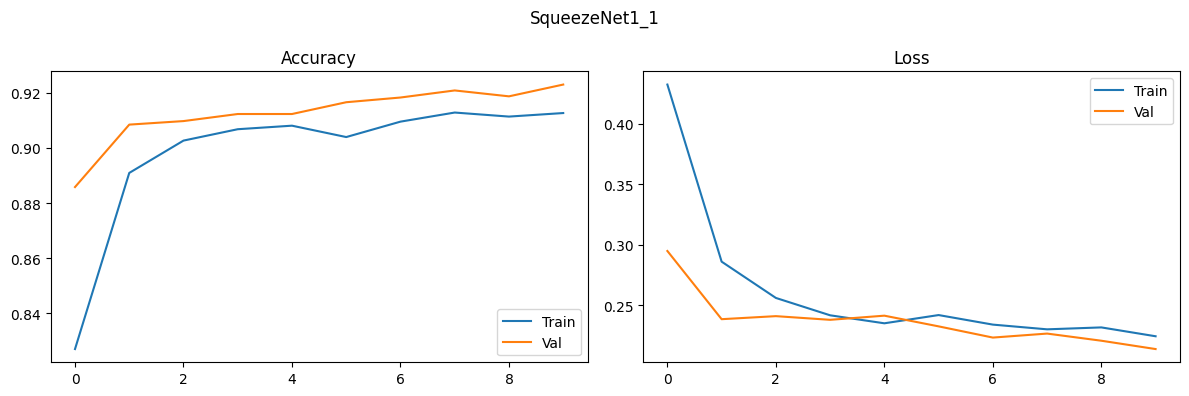


=== SqueezeNet1_1 - RESULTADOS EN TEST ===
Accuracy:  0.9242
Precision (macro): 0.9275
Recall (macro):    0.9259
F1 (macro):        0.9266
Parametros totales: 724,035
Tiempo de entrenamiento: 66.2 min

Reporte por clase:
              precision    recall  f1-score   support

    fusarium       0.92      0.90      0.91       786
        sana       0.97      0.96      0.96       685
    sigatoka       0.89      0.92      0.91       865

    accuracy                           0.92      2336
   macro avg       0.93      0.93      0.93      2336
weighted avg       0.92      0.92      0.92      2336



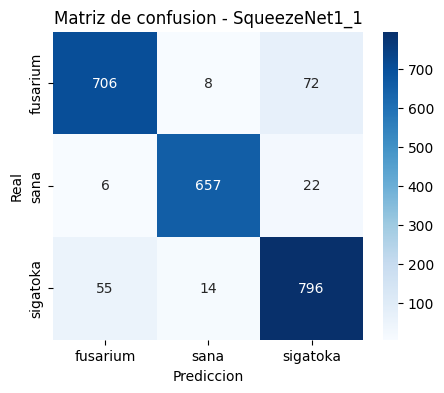

Resultado de 'SqueezeNet1_1' guardado en /content/drive/MyDrive/banana_piura_collectionds/comparativa_resultados.csv


(np.float64(0.9242294520547946),
 0.9274835981725391,
 0.9258580436602042,
 0.9265578667243153)

In [ ]:

# %% CELDA 5 - SqueezeNet 1.1
from torchvision.models import SqueezeNet1_1_Weights

NOMBRE = "SqueezeNet1_1"
model = models.squeezenet1_1(weights=SqueezeNet1_1_Weights.IMAGENET1K_V1)
for p in model.features.parameters():
    p.requires_grad = False
model.classifier[1] = nn.Conv2d(512, num_classes, kernel_size=1)
model.num_classes = num_classes
model = model.to(device)
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=LEARNING_RATE)

model, historial, tiempo = entrenar_modelo(model, optimizer, NOMBRE, train_loader, val_loader)
graficar_historial(historial, NOMBRE)
evaluar_y_mostrar(model, test_loader, class_names, NOMBRE, tiempo)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 212MB/s]


[ResNet50] Sin checkpoint previo, entrenando desde cero
[ResNet50] Epoca  1/10 | train_loss=0.4854 train_acc=0.8215 | val_loss=0.3332 val_acc=0.8725
[ResNet50] Epoca  2/10 | train_loss=0.3266 train_acc=0.8835 | val_loss=0.2793 val_acc=0.8961
[ResNet50] Epoca  3/10 | train_loss=0.3108 train_acc=0.8816 | val_loss=0.2648 val_acc=0.8999
[ResNet50] Epoca  4/10 | train_loss=0.2950 train_acc=0.8895 | val_loss=0.2853 val_acc=0.8909
[ResNet50] Epoca  5/10 | train_loss=0.2816 train_acc=0.8949 | val_loss=0.2413 val_acc=0.9106
[ResNet50] Epoca  6/10 | train_loss=0.2813 train_acc=0.8940 | val_loss=0.2377 val_acc=0.9115
[ResNet50] Epoca  7/10 | train_loss=0.2742 train_acc=0.8963 | val_loss=0.2567 val_acc=0.9008
[ResNet50] Epoca  8/10 | train_loss=0.2707 train_acc=0.8972 | val_loss=0.2316 val_acc=0.9123
[ResNet50] Epoca  9/10 | train_loss=0.2622 train_acc=0.9011 | val_loss=0.2292 val_acc=0.9119
[ResNet50] Epoca 10/10 | train_loss=0.2603 train_acc=0.9007 | val_loss=0.2272 val_acc=0.9162


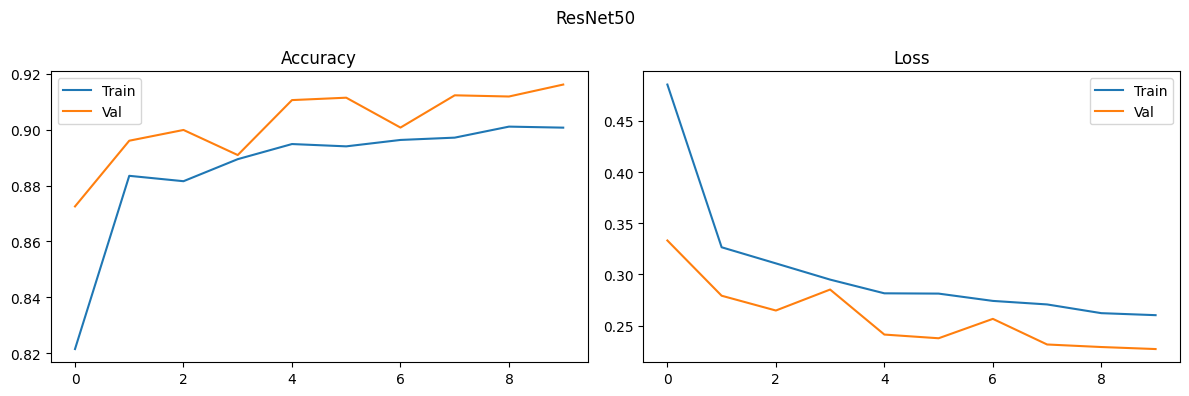


=== ResNet50 - RESULTADOS EN TEST ===
Accuracy:  0.9259
Precision (macro): 0.9302
Recall (macro):    0.9268
F1 (macro):        0.9279
Parametros totales: 23,514,179
Tiempo de entrenamiento: 77.4 min

Reporte por clase:
              precision    recall  f1-score   support

    fusarium       0.95      0.88      0.91       786
        sana       0.96      0.96      0.96       685
    sigatoka       0.88      0.94      0.91       865

    accuracy                           0.93      2336
   macro avg       0.93      0.93      0.93      2336
weighted avg       0.93      0.93      0.93      2336



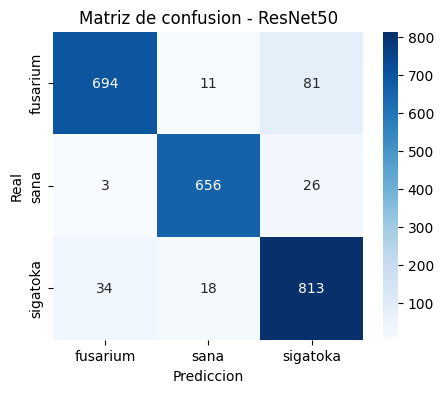

Resultado de 'ResNet50' guardado en /content/drive/MyDrive/banana_piura_collectionds/comparativa_resultados.csv


(np.float64(0.9259417808219178),
 0.930248096891772,
 0.9268334268614155,
 0.9278507825188594)

In [8]:

# %% CELDA 6 - ResNet50
from torchvision.models import ResNet50_Weights

NOMBRE = "ResNet50"
model = models.resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)
for p in model.parameters():
    p.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)
optimizer = torch.optim.Adam(model.fc.parameters(), lr=LEARNING_RATE)

model, historial, tiempo = entrenar_modelo(model, optimizer, NOMBRE, train_loader, val_loader)
graficar_historial(historial, NOMBRE)
evaluar_y_mostrar(model, test_loader, class_names, NOMBRE, tiempo)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 152MB/s]


[EfficientNetB0] Sin checkpoint previo, entrenando desde cero
[EfficientNetB0] Epoca  1/10 | train_loss=0.5252 train_acc=0.8181 | val_loss=0.3730 val_acc=0.8760
[EfficientNetB0] Epoca  2/10 | train_loss=0.3619 train_acc=0.8679 | val_loss=0.3275 val_acc=0.8828
[EfficientNetB0] Epoca  3/10 | train_loss=0.3357 train_acc=0.8755 | val_loss=0.3046 val_acc=0.8888
[EfficientNetB0] Epoca  4/10 | train_loss=0.3230 train_acc=0.8797 | val_loss=0.2822 val_acc=0.8982
[EfficientNetB0] Epoca  5/10 | train_loss=0.3124 train_acc=0.8815 | val_loss=0.2978 val_acc=0.8854
[EfficientNetB0] Epoca  6/10 | train_loss=0.3016 train_acc=0.8855 | val_loss=0.2784 val_acc=0.8952
[EfficientNetB0] Epoca  7/10 | train_loss=0.2989 train_acc=0.8851 | val_loss=0.2723 val_acc=0.8995
[EfficientNetB0] Epoca  8/10 | train_loss=0.2986 train_acc=0.8866 | val_loss=0.2889 val_acc=0.8922
[EfficientNetB0] Epoca  9/10 | train_loss=0.2980 train_acc=0.8885 | val_loss=0.2761 val_acc=0.8956
[EfficientNetB0] Epoca 10/10 | train_loss=0.298

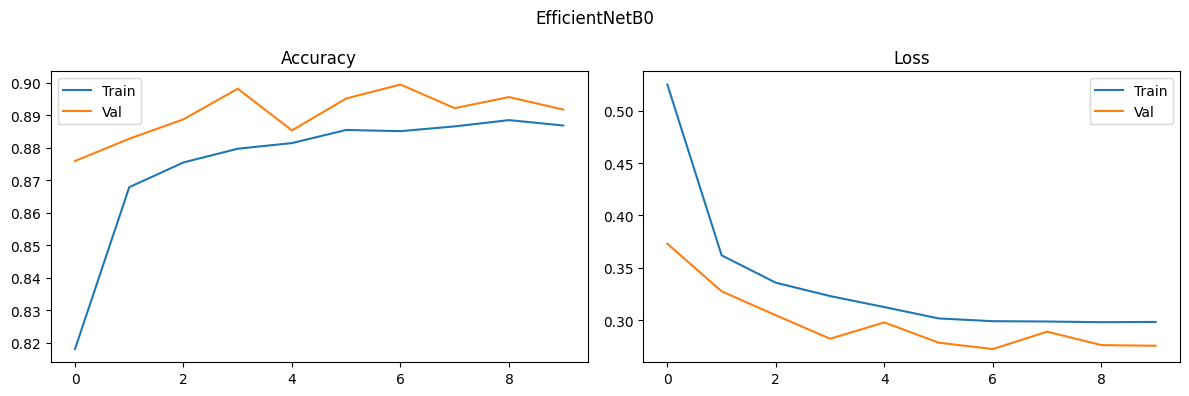


=== EfficientNetB0 - RESULTADOS EN TEST ===
Accuracy:  0.8964
Precision (macro): 0.9023
Recall (macro):    0.8974
F1 (macro):        0.8980
Parametros totales: 4,011,391
Tiempo de entrenamiento: 19.4 min

Reporte por clase:
              precision    recall  f1-score   support

    fusarium       0.94      0.83      0.88       786
        sana       0.92      0.94      0.93       685
    sigatoka       0.85      0.92      0.88       865

    accuracy                           0.90      2336
   macro avg       0.90      0.90      0.90      2336
weighted avg       0.90      0.90      0.90      2336



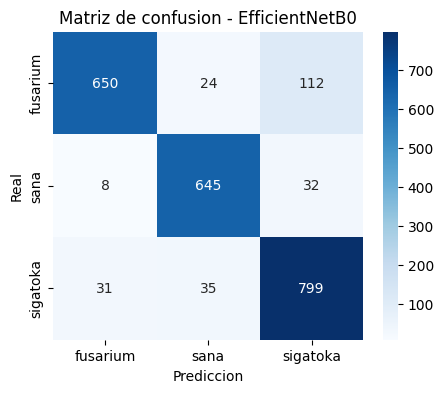

Resultado de 'EfficientNetB0' guardado en /content/drive/MyDrive/banana_piura_collectionds/comparativa_resultados.csv


(np.float64(0.896404109589041),
 0.9022950908320889,
 0.8974257571864978,
 0.897977063889786)

In [9]:

# %% CELDA 7 - EfficientNetB0
from torchvision.models import EfficientNet_B0_Weights

NOMBRE = "EfficientNetB0"
model = models.efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
for p in model.parameters():
    p.requires_grad = False
model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
model = model.to(device)
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=LEARNING_RATE)

model, historial, tiempo = entrenar_modelo(model, optimizer, NOMBRE, train_loader, val_loader)
graficar_historial(historial, NOMBRE)
evaluar_y_mostrar(model, test_loader, class_names, NOMBRE, tiempo)


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 146MB/s]


[DenseNet121] Sin checkpoint previo, entrenando desde cero
[DenseNet121] Epoca  1/10 | train_loss=0.5500 train_acc=0.7902 | val_loss=0.3497 val_acc=0.8743
[DenseNet121] Epoca  2/10 | train_loss=0.3468 train_acc=0.8764 | val_loss=0.2827 val_acc=0.8956
[DenseNet121] Epoca  3/10 | train_loss=0.3087 train_acc=0.8902 | val_loss=0.2729 val_acc=0.8986
[DenseNet121] Epoca  4/10 | train_loss=0.2916 train_acc=0.8931 | val_loss=0.2497 val_acc=0.9029
[DenseNet121] Epoca  5/10 | train_loss=0.2792 train_acc=0.8989 | val_loss=0.2514 val_acc=0.9042
[DenseNet121] Epoca  6/10 | train_loss=0.2790 train_acc=0.8958 | val_loss=0.2895 val_acc=0.8832
[DenseNet121] Epoca  7/10 | train_loss=0.2752 train_acc=0.8987 | val_loss=0.2430 val_acc=0.9055
[DenseNet121] Epoca  8/10 | train_loss=0.2595 train_acc=0.9023 | val_loss=0.2498 val_acc=0.9033
[DenseNet121] Epoca  9/10 | train_loss=0.2500 train_acc=0.9097 | val_loss=0.2250 val_acc=0.9127
[DenseNet121] Epoca 10/10 | train_loss=0.2429 train_acc=0.9114 | val_loss=0.2

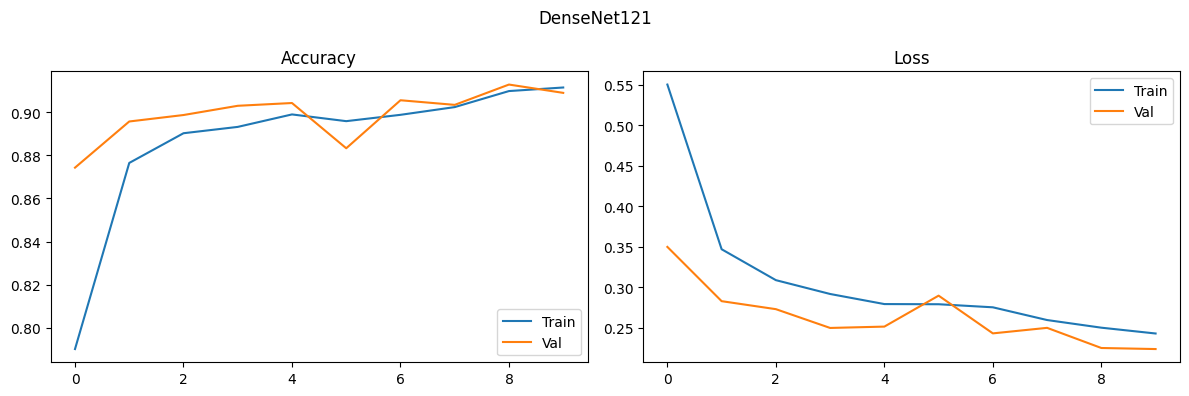


=== DenseNet121 - RESULTADOS EN TEST ===
Accuracy:  0.9238
Precision (macro): 0.9269
Recall (macro):    0.9251
F1 (macro):        0.9256
Parametros totales: 6,956,931
Tiempo de entrenamiento: 20.3 min

Reporte por clase:
              precision    recall  f1-score   support

    fusarium       0.89      0.94      0.91       786
        sana       0.97      0.94      0.95       685
    sigatoka       0.92      0.90      0.91       865

    accuracy                           0.92      2336
   macro avg       0.93      0.93      0.93      2336
weighted avg       0.92      0.92      0.92      2336



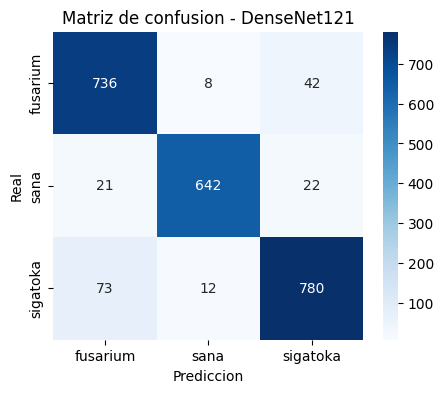

Resultado de 'DenseNet121' guardado en /content/drive/MyDrive/banana_piura_collectionds/comparativa_resultados.csv


(np.float64(0.9238013698630136),
 0.9269020412343378,
 0.9251157166221141,
 0.9256449997275965)

In [10]:


# %% CELDA 8 - DenseNet121
from torchvision.models import DenseNet121_Weights

NOMBRE = "DenseNet121"
model = models.densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1)
for p in model.parameters():
    p.requires_grad = False
model.classifier = nn.Linear(model.classifier.in_features, num_classes)
model = model.to(device)
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=LEARNING_RATE)

model, historial, tiempo = entrenar_modelo(model, optimizer, NOMBRE, train_loader, val_loader)
graficar_historial(historial, NOMBRE)
evaluar_y_mostrar(model, test_loader, class_names, NOMBRE, tiempo)



  arquitectura  accuracy  precision_macro  recall_macro  f1_macro  num_parametros  tiempo_entrenamiento_min
      ResNet50    0.9259           0.9302        0.9268    0.9279        23514179                      77.4
 SqueezeNet1_1    0.9242           0.9275        0.9259    0.9266          724035                      66.2
   DenseNet121    0.9238           0.9269        0.9251    0.9256         6956931                      20.3
EfficientNetB0    0.8964           0.9023        0.8974    0.8980         4011391                      19.4


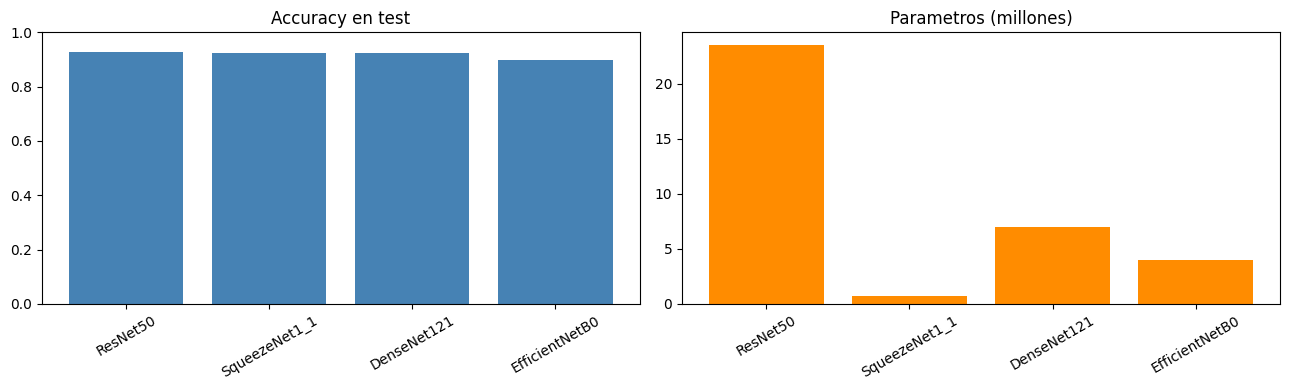

In [11]:

########################################################################
# CELDA FINAL: comparar todo lo evaluado hasta ahora
########################################################################

# %% CELDA 9 - Tabla y grafico comparativo entre arquitecturas
import pandas as pd

df = pd.read_csv(RESULTADOS_CSV)
df = df.sort_values("accuracy", ascending=False)
print(df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(df["arquitectura"], df["accuracy"].astype(float), color="steelblue")
axes[0].set_title("Accuracy en test")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_ylim(0, 1)

axes[1].bar(df["arquitectura"], df["num_parametros"].astype(float) / 1e6, color="darkorange")
axes[1].set_title("Parametros (millones)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

=== COMPARATIVA DE RENDIMIENTO Y TRAIN-TEST GAP ===


,arquitectura,train_accuracy,test_accuracy,train_test_gap
1,ResNet50,0.900743,0.9259,-0.025157
3,DenseNet121,0.911384,0.9238,-0.012416
0,SqueezeNet1_1,0.912669,0.9242,-0.011531
2,EfficientNetB0,0.886891,0.8964,-0.009509


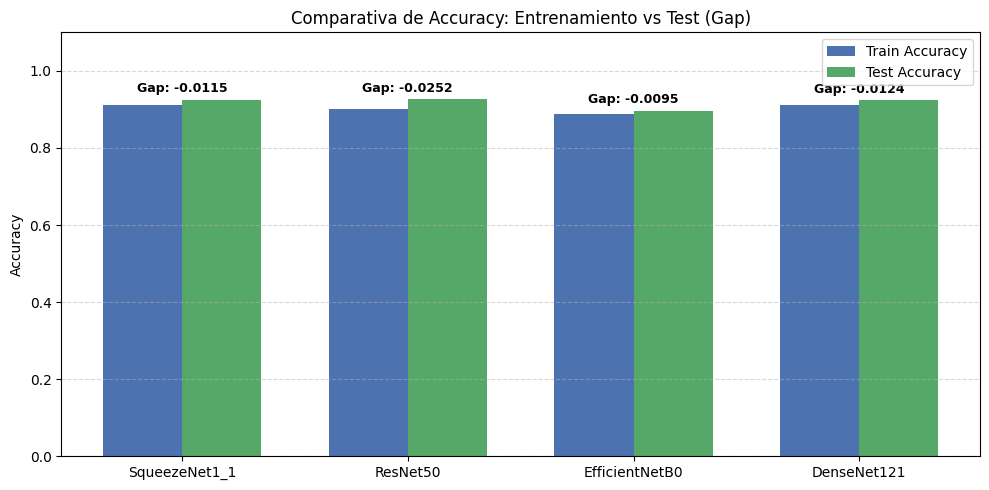

In [12]:
import os
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Cargar los resultados acumulados
if os.path.exists(RESULTADOS_CSV):
    df_resultados = pd.read_csv(RESULTADOS_CSV)

    # Recuperar el Accuracy final de entrenamiento desde el checkpoint de cada modelo
    train_accs = {}
    for arq in df_resultados["arquitectura"]:
        checkpoint_path = f"{MODELOS_DIR}/checkpoint_{arq}.pt"
        if os.path.exists(checkpoint_path):
            ck = torch.load(checkpoint_path, map_location="cpu")
            # Obtenemos el accuracy de entrenamiento de la última época registrada
            train_accs[arq] = ck["historial"]["train_acc"][-1]
        else:
            train_accs[arq] = None

    # Agregar columna de Train Accuracy al DataFrame
    df_resultados["train_accuracy"] = df_resultados["arquitectura"].map(train_accs)

    # Asegurar que la columna 'accuracy' (test) sea float
    df_resultados["test_accuracy"] = df_resultados["accuracy"].astype(float)

    # Calcular la brecha (Gap)
    df_resultados["train_test_gap"] = df_resultados["train_accuracy"] - df_resultados["test_accuracy"]

    # Mostrar tabla detallada
    print("=== COMPARATIVA DE RENDIMIENTO Y TRAIN-TEST GAP ===")
    display(df_resultados[["arquitectura", "train_accuracy", "test_accuracy", "train_test_gap"]].sort_values("train_test_gap"))

    # Graficar la comparación
    plt.figure(figsize=(10, 5))
    x = range(len(df_resultados))
    width = 0.35

    plt.bar([i - width/2 for i in x], df_resultados["train_accuracy"], width, label="Train Accuracy", color="#4C72B0")
    plt.bar([i + width/2 for i in x], df_resultados["test_accuracy"], width, label="Test Accuracy", color="#55A868")

    plt.xticks(x, df_resultados["arquitectura"])
    plt.ylabel("Accuracy")
    plt.title("Comparativa de Accuracy: Entrenamiento vs Test (Gap)")
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    # Anotar la brecha sobre las barras
    for i, row in df_resultados.iterrows():
        gap = row["train_test_gap"]
        plt.text(i, max(row["train_accuracy"], row["test_accuracy"]) + 0.02, f"Gap: {gap:.4f}", ha='center', fontsize=9, fontweight='bold')

    plt.ylim(0, 1.1)
    plt.tight_layout()
    plt.show()
else:
    print(f"No se encontró el archivo de resultados en: {RESULTADOS_CSV}")

In [13]:
import itertools
import torch
import numpy as np
import pandas as pd
from statsmodels.stats.contingency_tables import mcnemar

# 1. Obtener las predicciones reales de cada modelo sobre el test_loader
def obtener_predicciones_correctas(nombre_arq, test_loader):
    modelo_path = f"{MODELOS_DIR}/mejor_{nombre_arq}.pt"
    checkpoint_path = f"{MODELOS_DIR}/checkpoint_{nombre_arq}.pt"

    # Reconstruir la arquitectura base
    if "SqueezeNet" in nombre_arq:
        modelo = models.squeezenet1_1()
        modelo.classifier[1] = nn.Conv2d(512, num_classes, kernel_size=1)
    elif "ResNet" in nombre_arq:
        modelo = models.resnet50()
        modelo.fc = nn.Linear(modelo.fc.in_features, num_classes)
    elif "EfficientNet" in nombre_arq:
        modelo = models.efficientnet_b0()
        modelo.classifier[1] = nn.Linear(modelo.classifier[1].in_features, num_classes)
    elif "DenseNet" in nombre_arq:
        modelo = models.densenet121()
        modelo.classifier = nn.Linear(modelo.classifier.in_features, num_classes)
    else:
        raise ValueError(f"Arquitectura {nombre_arq} no reconocida")

    # Cargar los mejores pesos
    modelo.load_state_dict(torch.load(modelo_path, map_location=device))
    modelo = modelo.to(device)
    modelo.eval()

    aciertos = []
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = imgs.to(device)
            outputs = modelo(imgs)
            _, preds = torch.max(outputs, 1)
            # Guardamos un array booleano de si acertó (True) o no (False)
            aciertos.extend((preds.cpu() == labels).numpy())
    return np.array(aciertos)

# 2. Recolectar aciertos para todos los modelos en el CSV
arquitecturas = df_resultados["arquitectura"].tolist()
aciertos_dict = {}

print("Obteniendo predicciones para el test de McNemar...")
for arq in arquitecturas:
    try:
        aciertos_dict[arq] = obtener_predicciones_correctas(arq, test_loader)
    except Exception as e:
        print(f"No se pudieron obtener predicciones para {arq}: {e}")

# 3. Calcular la matriz de McNemar
pares_analisis = []
for arq1, arq2 in itertools.combinations(aciertos_dict.keys(), 2):
    a1 = aciertos_dict[arq1]
    a2 = aciertos_dict[arq2]

    # Construir tabla de contingencia 2x2
    # [Ambos correctos,   Model1 correcto / Model2 incorrecto]
    # [Model2 correcto / Model1 incorrecto, Ambos incorrectos]
    celda_00 = np.sum(a1 & a2)
    celda_01 = np.sum(a1 & ~a2)  # Model1 correcto, Model2 incorrecto
    celda_10 = np.sum(~a1 & a2)  # Model1 incorrecto, Model2 correcto
    celda_11 = np.sum(~a1 & ~a2)

    tabla_contingencia = [[celda_00, celda_01], [celda_10, celda_11]]

    # Aplicar test de McNemar (con corrección de Edwards de continuidad por defecto)
    resultado = mcnemar(tabla_contingencia, exact=False, correction=True)
    p_value = resultado.pvalue

    significativo = "Sí" if p_value < 0.05 else "No"

    pares_analisis.append({
        "Modelo 1": arq1,
        "Modelo 2": arq2,
        "Error M1 (Solo M1 falla)": celda_10,
        "Error M2 (Solo M2 falla)": celda_01,
        "p-value": f"{p_value:.5f}",
        "Diferencia Significativa (<0.05)": significativo
    })

df_mcnemar = pd.DataFrame(pares_analisis)
print("\n=== RESULTADOS DE LA PRUEBA DE MCNEMAR ===")
display(df_mcnemar)

Obteniendo predicciones para el test de McNemar...

=== RESULTADOS DE LA PRUEBA DE MCNEMAR ===


,Modelo 1,Modelo 2,Error M1 (Solo M1 falla),Error M2 (Solo M2 falla),p-value,Diferencia Significativa (<0.05)
0,SqueezeNet1_1,ResNet50,95,92,0.88372,No
1,SqueezeNet1_1,EfficientNetB0,86,152,0.00003,Sí
2,SqueezeNet1_1,DenseNet121,101,103,0.94418,No
3,ResNet50,EfficientNetB0,83,152,0.00001,Sí
4,ResNet50,DenseNet121,90,95,0.76869,No
5,EfficientNetB0,DenseNet121,164,100,0.00011,Sí
